# Cross-Model Common-Support Audit

This CPU analysis tests whether the Qwen–Gemma mapped-route difference survives differences in pair-pool composition.

[实验设置与运行说明](../../../docs/experiment_notes/09_appendix_factor_routes/0e5c973d4c248624.md)


In [1]:
from pathlib import Path
import os
import sys

from tqdm.auto import tqdm
from IPython.display import display

TOTAL_STAGES = 11
_progress = tqdm(total=TOTAL_STAGES, desc='Common-support audit', unit='stage')

def stage(label):
    if _progress.n < TOTAL_STAGES:
        _progress.update(1)
    _progress.set_postfix_str(label)
    print(f'[{_progress.n}/{TOTAL_STAGES}] {label}')


Common-support audit:   0%|          | 0/11 [00:00<?, ?stage/s]

## 1. Locate and validate completed artifacts


In [2]:
stage('Locating project and completed synthesis')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

def find_project_root():
    configured = os.environ.get('VISUALTORQUE_ROOT')
    candidates = []
    if configured:
        candidates.append(Path(configured).expanduser())
    if IN_COLAB:
        candidates.extend((
            Path('/content/drive/MyDrive/VisualTorque'),
            Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
        ))
    for base in (Path.cwd(), *Path.cwd().parents):
        candidates.extend((base, base / 'VisualTorque'))
    checked = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in checked:
            continue
        checked.add(candidate)
        if (
            (candidate / 'results' / 'cross_model'
             / 'qwen_gemma_mechanism_synthesis_v1'
             / 'unified_pair_level.csv').is_file()
        ):
            return candidate
    raise FileNotFoundError(
        'Could not locate the completed synthesis. Mount Drive, start '
        'Jupyter inside the repository, or set VISUALTORQUE_ROOT.'
    )

PROJECT_ROOT = find_project_root()
RESULTS_ROOT = PROJECT_ROOT / 'results'
SYNTHESIS_DIR = (
    RESULTS_ROOT / 'cross_model' / 'qwen_gemma_mechanism_synthesis_v1'
)
QWEN_ANALYSIS = (
    RESULTS_ROOT / 'Qwen__Qwen3.5-9B'
    / 'competence_grouped_route_confirmatory_v1' / 'analysis'
)
GEMMA_ANALYSIS = (
    RESULTS_ROOT / 'google__gemma-4-12B-it'
    / 'competence_grouped_route_gemma_replication_v3' / 'analysis'
)
OUTPUT_DIR = (
    RESULTS_ROOT / 'cross_model' / 'cross_model_common_support_audit_v1'
)
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Synthesis:', SYNTHESIS_DIR)
print('Output:', OUTPUT_DIR)


[1/11] Locating project and completed synthesis
Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque
Synthesis: /content/drive/MyDrive/VisualTorque/results/cross_model/qwen_gemma_mechanism_synthesis_v1
Output: /content/drive/MyDrive/VisualTorque/results/cross_model/cross_model_common_support_audit_v1


In [3]:
stage('Loading pair-level effects and donor covariates')

import hashlib
import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SOURCE_PATHS = {
    'unified_pair_level': SYNTHESIS_DIR / 'unified_pair_level.csv',
    'synthesis_decision': SYNTHESIS_DIR / 'decision_summary.json',
    'qwen_manifest': QWEN_ANALYSIS / 'pair_manifest.csv',
    'gemma_manifest': GEMMA_ANALYSIS / 'pair_manifest.csv',
}
missing = [str(path) for path in SOURCE_PATHS.values() if not path.is_file()]
assert not missing, 'Missing required artifacts:\n' + '\n'.join(missing)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def as_bool(series):
    if series.dtype == bool:
        return series.astype(bool)
    mapped = series.astype(str).str.lower().map({
        'true': True, 'false': False, '1': True, '0': False,
    })
    assert mapped.notna().all(), sorted(series.astype(str).unique())
    return mapped.astype(bool)

pair_frame = pd.read_csv(SOURCE_PATHS['unified_pair_level'])
required = {
    'model', 'pair_id', 'mapped_site', 'query_both_correct',
    'edit_type', 'relevant_task', 'task_family',
    'recovery_value_minus_outcome', 'margin_value_minus_outcome',
    'natural_effect_norm', 'log_natural_effect_norm',
    'absolute_value_gap',
}
assert required <= set(pair_frame.columns), sorted(required - set(pair_frame.columns))
pair_frame['query_both_correct'] = as_bool(pair_frame['query_both_correct'])
pair_frame['pair_id'] = pair_frame['pair_id'].astype(str)
assert set(pair_frame['model']) == {'Qwen', 'Gemma'}
assert set(pair_frame['mapped_site']) == {'all_text', 'options'}
assert pair_frame.groupby(['model', 'mapped_site'])['pair_id'].nunique().eq(192).all()

manifest_frames = []
for model, key in (('Qwen', 'qwen_manifest'), ('Gemma', 'gemma_manifest')):
    manifest = pd.read_csv(SOURCE_PATHS[key])
    manifest['pair_id'] = manifest['pair_id'].astype(str)
    donor_columns = [
        'pair_id', 'same_task_value_nuisance_distance',
        'outcome_only_nuisance_distance',
    ]
    assert set(donor_columns) <= set(manifest.columns), (
        model, sorted(set(donor_columns) - set(manifest.columns))
    )
    donor = manifest[donor_columns].drop_duplicates('pair_id').copy()
    donor['model'] = model
    manifest_frames.append(donor)
donor_frame = pd.concat(manifest_frames, ignore_index=True)
pair_frame = pair_frame.merge(
    donor_frame, on=['model', 'pair_id'], how='left',
    validate='many_to_one',
)
assert pair_frame[
    ['same_task_value_nuisance_distance',
     'outcome_only_nuisance_distance']
].notna().all().all()
pair_frame['donor_distance_mean'] = pair_frame[[
    'same_task_value_nuisance_distance',
    'outcome_only_nuisance_distance',
]].mean(axis=1)
pair_frame['donor_distance_gap'] = (
    pair_frame['same_task_value_nuisance_distance']
    - pair_frame['outcome_only_nuisance_distance']
).abs()
pair_frame['exact_stratum'] = (
    pair_frame['edit_type'].astype(str) + ' | '
    + pair_frame['relevant_task'].astype(str)
)
pair_frame['coarse_stratum'] = (
    pair_frame['edit_type'].astype(str) + ' | '
    + pair_frame['task_family'].astype(str)
)
synthesis_decision = json.loads(
    SOURCE_PATHS['synthesis_decision'].read_text('utf-8')
)
assert synthesis_decision['route_decision'] == 'qwen_specific_mapped_route_supported'
print('Rows:', len(pair_frame))
print('Successful unique pairs:')
display(pair_frame[pair_frame['query_both_correct']].groupby(
    'model')['pair_id'].nunique().rename('n').reset_index())


[2/11] Loading pair-level effects and donor covariates
Rows: 768
Successful unique pairs:


,model,n
0,Gemma,74
1,Qwen,81


In [4]:
stage('Freezing common-support protocol')

SEED = 20260820
BOOTSTRAP_REPLICATES = 5000
PERMUTATION_REPLICATES = 10000
ALPHA = 0.05
MIN_EXACT_PER_MODEL = 4
MIN_COARSE_PER_MODEL = 8
MIN_PRIMARY_BLOCKS = 2
MIN_PRIMARY_COMMON_N = 24
MAX_ACCEPTABLE_SMD = 0.25
COVARIATES = (
    'log_natural_effect_norm', 'absolute_value_gap',
    'same_task_value_nuisance_distance',
    'outcome_only_nuisance_distance', 'donor_distance_gap',
)
METRICS = {
    'recovery': 'recovery_value_minus_outcome',
    'margin': 'margin_value_minus_outcome',
}
PROTOCOL_PATH = OUTPUT_DIR / 'common_support_protocol.json'

protocol_identity = {
    'schema_version': 'cross-model-common-support-audit-1.0',
    'status': 'frozen robustness audit after cross-model synthesis',
    'source_hashes': {
        key: sha256_file(path) for key, path in SOURCE_PATHS.items()
    },
    'population': 'actual relevant-query source and target both correct',
    'primary_strata': ['edit_type', 'relevant_task'],
    'secondary_strata': ['edit_type', 'task_family'],
    'minimum_exact_per_model': MIN_EXACT_PER_MODEL,
    'minimum_coarse_per_model': MIN_COARSE_PER_MODEL,
    'minimum_primary_blocks': MIN_PRIMARY_BLOCKS,
    'minimum_primary_common_n_per_model': MIN_PRIMARY_COMMON_N,
    'covariates': list(COVARIATES),
    'estimators': [
        'overlap-weighted exact-stratum mean difference',
        'one-to-one nearest cross-model matching within exact strata',
        'exact-stratum fixed-effect regression with covariate adjustment',
    ],
    'multiplicity': 'BH across two mapped sites within metric and estimator',
    'bootstrap_unit': 'counterfactual pair',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'permutation_replicates': PERMUTATION_REPLICATES,
    'maximum_acceptable_absolute_smd_after_matching': MAX_ACCEPTABLE_SMD,
    'alpha': ALPHA,
    'seed': SEED,
    'interpretation_limit': (
        'Common-support adjustment reduces observed pair-pool imbalance but '
        'cannot prove architecture alone caused the model difference. The '
        'claim remains restricted to the prespecified mapped sites, donor '
        'construction, and successful custom-query computations.'
    ),
}
if PROTOCOL_PATH.is_file():
    previous = json.loads(PROTOCOL_PATH.read_text('utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing audit used different sources or rules. Use a new versioned '
        'output directory instead of overwriting it.'
    )
else:
    write_json_atomic(PROTOCOL_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Protocol:', PROTOCOL_PATH)


[3/11] Freezing common-support protocol
Protocol: /content/drive/MyDrive/VisualTorque/results/cross_model/cross_model_common_support_audit_v1/common_support_protocol.json


## 2. Shared support and statistical utilities


In [5]:
stage('Enumerating exact and coarse common support')

successful_pairs = pair_frame[
    pair_frame['query_both_correct']
].drop_duplicates(['model', 'pair_id']).copy()

def support_table(frame, stratum_column, minimum):
    counts = frame.groupby(
        [stratum_column, 'model']
    )['pair_id'].nunique().unstack(fill_value=0)
    for model in ('Qwen', 'Gemma'):
        if model not in counts:
            counts[model] = 0
    counts = counts[['Qwen', 'Gemma']].reset_index()
    counts['common_n_per_model'] = counts[['Qwen', 'Gemma']].min(axis=1)
    counts['eligible'] = (
        (counts['Qwen'] >= minimum)
        & (counts['Gemma'] >= minimum)
    )
    counts['support_level'] = stratum_column
    return counts

exact_support = support_table(
    successful_pairs, 'exact_stratum', MIN_EXACT_PER_MODEL
)
coarse_support = support_table(
    successful_pairs, 'coarse_stratum', MIN_COARSE_PER_MODEL
)
support = pd.concat([exact_support, coarse_support], ignore_index=True)
support.to_csv(OUTPUT_DIR / 'common_support_strata.csv', index=False)
eligible_exact = set(exact_support.loc[
    exact_support['eligible'], 'exact_stratum'
])
eligible_coarse = set(coarse_support.loc[
    coarse_support['eligible'], 'coarse_stratum'
])
primary_common_n = int(exact_support.loc[
    exact_support['eligible'], 'common_n_per_model'
].sum())
print('Eligible exact blocks:', len(eligible_exact))
print('Primary common n per model:', primary_common_n)
display(exact_support.sort_values(
    ['eligible', 'common_n_per_model'], ascending=[False, False]
))
print('Coarse support sensitivity:')
display(coarse_support.sort_values(
    ['eligible', 'common_n_per_model'], ascending=[False, False]
))


[4/11] Enumerating exact and coarse common support
Eligible exact blocks: 5
Primary common n per model: 70


model,exact_stratum,Qwen,Gemma,common_n_per_model,eligible,support_level
1,add_unit | right_units,21,18,18,True,exact_stratum
0,add_unit | left_units,18,16,16,True,exact_stratum
7,redecompose | right_units,16,17,16,True,exact_stratum
6,redecompose | left_units,17,15,15,True,exact_stratum
3,mirror | net_torque,7,5,5,True,exact_stratum
2,mirror | left_units,0,3,0,False,exact_stratum
4,move_stack | left_torque,1,0,0,False,exact_stratum
5,move_stack | right_torque,1,0,0,False,exact_stratum


Coarse support sensitivity:


model,coarse_stratum,Qwen,Gemma,common_n_per_model,eligible,support_level
0,add_unit | units,39,34,34,True,coarse_stratum
4,redecompose | units,33,32,32,True,coarse_stratum
1,mirror | torque,7,5,5,False,coarse_stratum
2,mirror | units,0,3,0,False,coarse_stratum
3,move_stack | torque,2,0,0,False,coarse_stratum


In [6]:
stage('Defining deterministic pair-level inference')

def stable_seed(label):
    digest = hashlib.sha256(f'{SEED}:{label}'.encode()).hexdigest()
    return int(digest[:8], 16)

def bh_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    result = np.full(values.shape, np.nan)
    valid = np.isfinite(values)
    if not valid.any():
        return result
    observed = values[valid]
    order = np.argsort(observed)
    ranked = observed[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    restored = np.empty_like(adjusted)
    restored[order] = np.minimum(adjusted, 1.0)
    result[valid] = restored
    return result

def paired_test(values, label):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return dict(n=0, effect=np.nan, ci_low=np.nan, ci_high=np.nan,
                    p_value=np.nan)
    rng = np.random.default_rng(stable_seed(label))
    counts = rng.multinomial(
        len(values), np.full(len(values), 1 / len(values)),
        size=BOOTSTRAP_REPLICATES,
    )
    bootstrap = counts @ values / len(values)
    signs = rng.choice(
        np.asarray([-1.0, 1.0]),
        size=(PERMUTATION_REPLICATES, len(values)),
    )
    permutation = signs @ values / len(values)
    observed = float(values.mean())
    return {
        'n': int(len(values)), 'effect': observed,
        'ci_low': float(np.quantile(bootstrap, 0.025)),
        'ci_high': float(np.quantile(bootstrap, 0.975)),
        'p_value': float(
            (1 + np.sum(permutation >= observed))
            / (PERMUTATION_REPLICATES + 1)
        ),
    }

def stratified_difference(frame, value_column, stratum_column,
                          eligible, label):
    blocks = []
    for stratum, group in frame[
        frame[stratum_column].isin(eligible)
    ].groupby(stratum_column, sort=True):
        qwen = group.loc[group['model'] == 'Qwen', value_column]
        gemma = group.loc[group['model'] == 'Gemma', value_column]
        qwen = qwen.dropna().to_numpy(dtype=float)
        gemma = gemma.dropna().to_numpy(dtype=float)
        if len(qwen) and len(gemma):
            weight = min(len(qwen), len(gemma))
            blocks.append((stratum, qwen, gemma, weight))
    if not blocks:
        return dict(block_count=0, common_n_per_model=0,
                    effect=np.nan, ci_low=np.nan, ci_high=np.nan,
                    p_value=np.nan)
    weights = np.asarray([row[3] for row in blocks], dtype=float)
    weights /= weights.sum()
    observed = float(weights @ np.asarray([
        qwen.mean() - gemma.mean() for _, qwen, gemma, _ in blocks
    ]))
    rng = np.random.default_rng(stable_seed(label))
    bootstrap = np.zeros(BOOTSTRAP_REPLICATES)
    permutation = np.zeros(PERMUTATION_REPLICATES)
    for weight, (_, qwen, gemma, _) in zip(weights, blocks):
        qwen_counts = rng.multinomial(
            len(qwen), np.full(len(qwen), 1 / len(qwen)),
            size=BOOTSTRAP_REPLICATES,
        )
        gemma_counts = rng.multinomial(
            len(gemma), np.full(len(gemma), 1 / len(gemma)),
            size=BOOTSTRAP_REPLICATES,
        )
        bootstrap += weight * (
            qwen_counts @ qwen / len(qwen)
            - gemma_counts @ gemma / len(gemma)
        )
        pooled = np.concatenate([qwen, gemma])
        order = np.argsort(
            rng.random((PERMUTATION_REPLICATES, len(pooled))), axis=1
        )
        selected = pooled[order[:, :len(qwen)]].sum(axis=1)
        permutation += weight * (
            selected / len(qwen)
            - (pooled.sum() - selected) / len(gemma)
        )
    return {
        'block_count': int(len(blocks)),
        'common_n_per_model': int(sum(row[3] for row in blocks)),
        'effect': observed,
        'ci_low': float(np.quantile(bootstrap, 0.025)),
        'ci_high': float(np.quantile(bootstrap, 0.975)),
        'p_value': float(
            (1 + np.sum(permutation >= observed))
            / (PERMUTATION_REPLICATES + 1)
        ),
    }

smoke = paired_test(np.linspace(0.1, 1.0, 20), 'positive-smoke')
assert smoke['effect'] > 0 and smoke['ci_low'] > 0
print('Statistical utility self-tests passed.')


[5/11] Defining deterministic pair-level inference
Statistical utility self-tests passed.


## 3. Exact-stratum, matched, and regression-adjusted contrasts


In [7]:
stage('Running exact and coarse stratified comparisons')

successful = pair_frame[pair_frame['query_both_correct']].copy()
stratified_rows = []
block_rows = []
leaveout_rows = []
for metric, value_column in METRICS.items():
    for mapped_site in ('all_text', 'options'):
        site = successful[successful['mapped_site'] == mapped_site].copy()
        for support_level, stratum_column, eligible in (
            ('exact', 'exact_stratum', eligible_exact),
            ('coarse', 'coarse_stratum', eligible_coarse),
        ):
            stratified_rows.append({
                'estimator': f'{support_level}_stratified',
                'support_level': support_level,
                'mapped_site': mapped_site, 'metric': metric,
                **stratified_difference(
                    site, value_column, stratum_column, eligible,
                    f'{support_level}:{mapped_site}:{metric}',
                ),
            })
        exact_site = site[site['exact_stratum'].isin(eligible_exact)]
        for stratum, group in exact_site.groupby('exact_stratum', sort=True):
            qwen = group.loc[group['model'] == 'Qwen', value_column].dropna()
            gemma = group.loc[group['model'] == 'Gemma', value_column].dropna()
            if len(qwen) and len(gemma):
                block_rows.append({
                    'mapped_site': mapped_site, 'metric': metric,
                    'exact_stratum': stratum,
                    'qwen_n': len(qwen), 'gemma_n': len(gemma),
                    'common_n': min(len(qwen), len(gemma)),
                    'effect': float(qwen.mean() - gemma.mean()),
                })
        for held_out in sorted(eligible_exact):
            retained = set(eligible_exact) - {held_out}
            result = stratified_difference(
                site, value_column, 'exact_stratum', retained,
                f'leaveout:{mapped_site}:{metric}:{held_out}',
            )
            leaveout_rows.append({
                'mapped_site': mapped_site, 'metric': metric,
                'held_out_stratum': held_out, **result,
            })

stratified_tests = pd.DataFrame(stratified_rows)
block_effects = pd.DataFrame(block_rows)
leaveout = pd.DataFrame(leaveout_rows)
stratified_tests['q_bh'] = np.nan
for keys, indices in stratified_tests.groupby(
    ['support_level', 'metric']
).groups.items():
    stratified_tests.loc[indices, 'q_bh'] = bh_adjust(
        stratified_tests.loc[indices, 'p_value']
    )
stratified_tests['passes_fdr'] = (
    (stratified_tests['effect'] > 0)
    & (stratified_tests['ci_low'] > 0)
    & (stratified_tests['q_bh'] < ALPHA)
)
stratified_tests.to_csv(
    OUTPUT_DIR / 'stratified_common_support_tests.csv', index=False
)
block_effects.to_csv(OUTPUT_DIR / 'exact_block_effects.csv', index=False)
leaveout.to_csv(OUTPUT_DIR / 'leave_one_stratum_out.csv', index=False)
display(stratified_tests)
print('Exact-stratum effects:')
display(block_effects)


[6/11] Running exact and coarse stratified comparisons


,estimator,support_level,mapped_site,metric,block_count,common_n_per_model,effect,ci_low,ci_high,p_value,q_bh,passes_fdr
0,exact_stratified,exact,all_text,recovery,5,70,0.285340,0.198828,0.364593,0.0001,0.0001,True
1,coarse_stratified,coarse,all_text,recovery,2,66,0.313412,0.227807,0.398631,0.0001,0.0001,True
2,exact_stratified,exact,options,recovery,5,70,0.200561,0.131820,0.266052,0.0001,0.0001,True
3,coarse_stratified,coarse,options,recovery,2,66,0.217726,0.147514,0.286888,0.0001,0.0001,True
4,exact_stratified,exact,all_text,margin,5,70,2.206667,1.213429,3.148758,0.0001,0.0002,True
5,coarse_stratified,coarse,all_text,margin,2,66,2.381566,1.340208,3.426792,0.0001,0.0002,True
6,exact_stratified,exact,options,margin,5,70,1.479228,0.666502,2.279457,0.0002,0.0002,True
7,coarse_stratified,coarse,options,margin,2,66,1.590242,0.686887,2.443780,0.0002,0.0002,True


Exact-stratum effects:


,mapped_site,metric,exact_stratum,qwen_n,gemma_n,common_n,effect
0,all_text,recovery,add_unit | left_units,18,16,16,0.336001
1,all_text,recovery,add_unit | right_units,21,18,18,0.412157
2,all_text,recovery,mirror | net_torque,7,5,5,-0.085700
3,all_text,recovery,redecompose | left_units,17,15,15,0.229214
4,all_text,recovery,redecompose | right_units,16,17,16,0.260577
5,options,recovery,add_unit | left_units,18,16,16,0.190739
6,options,recovery,add_unit | right_units,21,18,18,0.307373
7,options,recovery,mirror | net_torque,7,5,5,-0.025347
8,options,recovery,redecompose | left_units,17,15,15,0.148427
9,options,recovery,redecompose | right_units,16,17,16,0.209693


In [8]:
stage('Matching cross-model pairs and auditing balance')

def standardized_mean_difference(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    pooled = np.sqrt((np.nanvar(left, ddof=1) + np.nanvar(right, ddof=1)) / 2)
    if not np.isfinite(pooled) or pooled == 0:
        return 0.0 if np.isclose(np.nanmean(left), np.nanmean(right)) else np.nan
    return float((np.nanmean(left) - np.nanmean(right)) / pooled)

def nearest_matches(frame):
    match_rows = []
    for stratum, group in frame.groupby('exact_stratum', sort=True):
        qwen = group[group['model'] == 'Qwen'].copy().sort_values('pair_id')
        gemma = group[group['model'] == 'Gemma'].copy().sort_values('pair_id')
        if qwen.empty or gemma.empty:
            continue
        pooled = group[list(COVARIATES)]
        scale = pooled.std(ddof=0).replace(0, 1).fillna(1)
        center = pooled.mean()
        q_features = (qwen[list(COVARIATES)] - center) / scale
        g_features = (gemma[list(COVARIATES)] - center) / scale
        if len(qwen) <= len(gemma):
            small_model, small, small_features = 'Qwen', qwen, q_features
            large, large_features = gemma, g_features
        else:
            small_model, small, small_features = 'Gemma', gemma, g_features
            large, large_features = qwen, q_features
        available = set(large.index)
        for small_index in small.index:
            if not available:
                break
            candidates = sorted(available)
            delta = (
                large_features.loc[candidates]
                - small_features.loc[small_index]
            )
            distance = np.sqrt((delta ** 2).mean(axis=1))
            large_index = distance.sort_values(kind='mergesort').index[0]
            if small_model == 'Qwen':
                qwen_index, gemma_index = small_index, large_index
            else:
                qwen_index, gemma_index = large_index, small_index
            match_rows.append({
                'mapped_site': frame['mapped_site'].iloc[0],
                'exact_stratum': stratum,
                'qwen_index': int(qwen_index),
                'gemma_index': int(gemma_index),
                'qwen_pair_id': str(frame.loc[qwen_index, 'pair_id']),
                'gemma_pair_id': str(frame.loc[gemma_index, 'pair_id']),
                'distance': float(distance.loc[large_index]),
            })
            available.remove(large_index)
    return pd.DataFrame(match_rows)

match_sets = []
balance_rows = []
matched_test_rows = []
for mapped_site in ('all_text', 'options'):
    site = successful[
        (successful['mapped_site'] == mapped_site)
        & successful['exact_stratum'].isin(eligible_exact)
    ].copy()
    matches = nearest_matches(site)
    assert len(matches), mapped_site
    match_sets.append(matches)
    before_q = site[site['model'] == 'Qwen']
    before_g = site[site['model'] == 'Gemma']
    after_q = site.loc[matches['qwen_index']]
    after_g = site.loc[matches['gemma_index']]
    for covariate in COVARIATES:
        balance_rows.append({
            'mapped_site': mapped_site, 'covariate': covariate,
            'before_smd': standardized_mean_difference(
                before_q[covariate], before_g[covariate]
            ),
            'after_smd': standardized_mean_difference(
                after_q[covariate], after_g[covariate]
            ),
        })
    for metric, value_column in METRICS.items():
        difference = (
            after_q[value_column].to_numpy(dtype=float)
            - after_g[value_column].to_numpy(dtype=float)
        )
        for maximum_distance in (1.0, 1.5, 2.0, np.inf):
            keep = matches['distance'].to_numpy() <= maximum_distance
            matched_test_rows.append({
                'mapped_site': mapped_site, 'metric': metric,
                'maximum_distance': maximum_distance,
                **paired_test(
                    difference[keep],
                    f'matched:{mapped_site}:{metric}:{maximum_distance}',
                ),
            })

matched_pairs = pd.concat(match_sets, ignore_index=True)
balance = pd.DataFrame(balance_rows)
matched_tests = pd.DataFrame(matched_test_rows)
matched_tests['q_bh'] = np.nan
primary_match = np.isinf(matched_tests['maximum_distance'])
for metric, indices in matched_tests[primary_match].groupby('metric').groups.items():
    matched_tests.loc[indices, 'q_bh'] = bh_adjust(
        matched_tests.loc[indices, 'p_value']
    )
matched_tests['passes_fdr'] = (
    (matched_tests['effect'] > 0)
    & (matched_tests['ci_low'] > 0)
    & (matched_tests['q_bh'] < ALPHA)
)
matched_pairs.to_csv(OUTPUT_DIR / 'cross_model_matched_pairs.csv', index=False)
balance.to_csv(OUTPUT_DIR / 'covariate_balance.csv', index=False)
matched_tests.to_csv(OUTPUT_DIR / 'matched_common_support_tests.csv', index=False)
print('Matched pairs by site:', matched_pairs.groupby('mapped_site').size().to_dict())
display(balance)
display(matched_tests)


[7/11] Matching cross-model pairs and auditing balance
Matched pairs by site: {'all_text': 70, 'options': 70}


,mapped_site,covariate,before_smd,after_smd
0,all_text,log_natural_effect_norm,-2.401309,-2.375142
1,all_text,absolute_value_gap,0.011602,-0.045351
2,all_text,same_task_value_nuisance_distance,0.383325,0.196178
3,all_text,outcome_only_nuisance_distance,0.348101,0.167639
4,all_text,donor_distance_gap,0.194847,-0.049330
5,options,log_natural_effect_norm,-2.401309,-2.375142
6,options,absolute_value_gap,0.011602,-0.045351
7,options,same_task_value_nuisance_distance,0.383325,0.196178
8,options,outcome_only_nuisance_distance,0.348101,0.167639
9,options,donor_distance_gap,0.194847,-0.049330


,mapped_site,metric,maximum_distance,n,effect,ci_low,ci_high,p_value,q_bh,passes_fdr
0,all_text,recovery,1.0,40,0.262102,0.159919,0.357282,0.000100,NaN,False
1,all_text,recovery,1.5,60,0.293576,0.200675,0.387121,0.000100,NaN,False
2,all_text,recovery,2.0,67,0.298559,0.212879,0.384726,0.000100,NaN,False
3,all_text,recovery,inf,70,0.301529,0.222412,0.383224,0.000100,0.0001,True
4,all_text,margin,1.0,40,1.906250,0.721074,3.141426,0.002400,NaN,False
5,all_text,margin,1.5,60,2.356771,1.419557,3.292266,0.000100,NaN,False
6,all_text,margin,2.0,67,2.288713,1.358057,3.222983,0.000100,NaN,False
7,all_text,margin,inf,70,2.375446,1.486105,3.300011,0.000100,0.0001,True
8,options,recovery,1.0,40,0.190168,0.104061,0.269642,0.000100,NaN,False
9,options,recovery,1.5,60,0.204482,0.122910,0.278892,0.000100,NaN,False


In [9]:
stage('Running exact-stratum fixed-effect regression')

def regression_design(frame, model_values=None):
    working = frame.copy()
    covariates = working[list(COVARIATES)].astype(float)
    covariate_scale = covariates.std(ddof=0).replace(0, 1).fillna(1)
    covariates = (covariates - covariates.mean()) / covariate_scale
    strata = pd.get_dummies(
        working['exact_stratum'], prefix='stratum', drop_first=True,
        dtype=float,
    )
    nuisance = np.column_stack([
        np.ones(len(working)), covariates.to_numpy(dtype=float),
        strata.to_numpy(dtype=float),
    ])
    model = (
        (working['model'] == 'Qwen').to_numpy(dtype=float)
        if model_values is None else np.asarray(model_values, dtype=float)
    )
    return model, nuisance

def adjusted_model_effect(frame, value_column, label):
    working = frame.dropna(subset=[value_column, *COVARIATES]).copy()
    model, nuisance = regression_design(working)
    outcome = working[value_column].to_numpy(dtype=float)
    nuisance_pinv = np.linalg.pinv(nuisance)
    outcome_residual = outcome - nuisance @ (nuisance_pinv @ outcome)

    def coefficient(model_vector, nuisance_matrix=nuisance):
        residual = model_vector - nuisance_matrix @ (
            np.linalg.pinv(nuisance_matrix) @ model_vector
        )
        denominator = float(residual @ residual)
        return float(residual @ outcome_residual / denominator) if denominator > 0 else np.nan

    observed = coefficient(model)
    rng = np.random.default_rng(stable_seed(label))
    group_indices = [
        group.index.to_numpy()
        for _, group in working.groupby(['exact_stratum', 'model'], sort=True)
    ]
    position = {index: offset for offset, index in enumerate(working.index)}
    bootstrap = np.zeros(BOOTSTRAP_REPLICATES)
    for replicate in tqdm(
        range(BOOTSTRAP_REPLICATES),
        desc=f'Regression bootstrap {label}', unit='replicate',
        leave=False,
    ):
        sampled_labels = []
        for indices in group_indices:
            sampled_labels.extend(rng.choice(indices, len(indices), replace=True))
        sampled_positions = np.asarray([position[index] for index in sampled_labels])
        sampled = working.iloc[sampled_positions].copy()
        sampled_model, sampled_nuisance = regression_design(sampled)
        sampled_outcome = sampled[value_column].to_numpy(dtype=float)
        design = np.column_stack([sampled_model, sampled_nuisance])
        bootstrap[replicate] = np.linalg.lstsq(
            design, sampled_outcome, rcond=None
        )[0][0]

    permutations = np.tile(model, (PERMUTATION_REPLICATES, 1))
    for _, group in working.groupby('exact_stratum', sort=True):
        positions = np.asarray([position[index] for index in group.index])
        qwen_n = int((group['model'] == 'Qwen').sum())
        order = np.argsort(
            rng.random((PERMUTATION_REPLICATES, len(positions))), axis=1
        )
        permutations[:, positions] = 0.0
        selected = positions[order[:, :qwen_n]]
        row_indices = np.arange(PERMUTATION_REPLICATES)[:, None]
        permutations[row_indices, selected] = 1.0
    model_matrix = permutations.T
    residual_matrix = model_matrix - nuisance @ (nuisance_pinv @ model_matrix)
    numerator = outcome_residual @ residual_matrix
    denominator = np.sum(residual_matrix ** 2, axis=0)
    permutation_effects = np.divide(
        numerator, denominator,
        out=np.full_like(numerator, np.nan), where=denominator > 0,
    )
    return {
        'n': int(len(working)),
        'block_count': int(working['exact_stratum'].nunique()),
        'effect': observed,
        'ci_low': float(np.nanquantile(bootstrap, 0.025)),
        'ci_high': float(np.nanquantile(bootstrap, 0.975)),
        'p_value': float(
            (1 + np.nansum(permutation_effects >= observed))
            / (1 + np.isfinite(permutation_effects).sum())
        ),
    }

regression_rows = []
for metric, value_column in METRICS.items():
    for mapped_site in ('all_text', 'options'):
        site = successful[
            (successful['mapped_site'] == mapped_site)
            & successful['exact_stratum'].isin(eligible_exact)
        ].copy()
        regression_rows.append({
            'mapped_site': mapped_site, 'metric': metric,
            **adjusted_model_effect(
                site, value_column,
                f'regression:{mapped_site}:{metric}',
            ),
        })
regression_tests = pd.DataFrame(regression_rows)
regression_tests['q_bh'] = np.nan
for metric, indices in regression_tests.groupby('metric').groups.items():
    regression_tests.loc[indices, 'q_bh'] = bh_adjust(
        regression_tests.loc[indices, 'p_value']
    )
regression_tests['passes_fdr'] = (
    (regression_tests['effect'] > 0)
    & (regression_tests['ci_low'] > 0)
    & (regression_tests['q_bh'] < ALPHA)
)
regression_tests.to_csv(
    OUTPUT_DIR / 'regression_adjusted_tests.csv', index=False
)
display(regression_tests)


[8/11] Running exact-stratum fixed-effect regression


Regression bootstrap regression:all_text:recovery:   0%|          | 0/5000 [00:00<?, ?replicate/s]

Regression bootstrap regression:options:recovery:   0%|          | 0/5000 [00:00<?, ?replicate/s]

Regression bootstrap regression:all_text:margin:   0%|          | 0/5000 [00:00<?, ?replicate/s]

Regression bootstrap regression:options:margin:   0%|          | 0/5000 [00:00<?, ?replicate/s]

,mapped_site,metric,n,block_count,effect,ci_low,ci_high,p_value,q_bh,passes_fdr
0,all_text,recovery,150,5,0.279480,0.058394,0.514828,0.0001,0.0001,True
1,options,recovery,150,5,0.162493,0.007595,0.341653,0.0001,0.0001,True
2,all_text,margin,150,5,3.191510,1.149412,5.060920,0.0001,0.0001,True
3,options,margin,150,5,1.725525,-0.084445,3.280235,0.0001,0.0001,False


## 4. Figures, decision gate, and report


[9/11] Rendering common-support figures


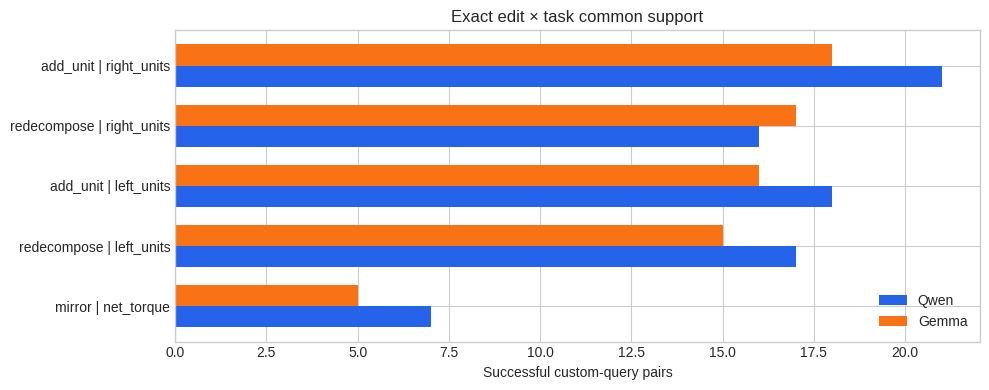

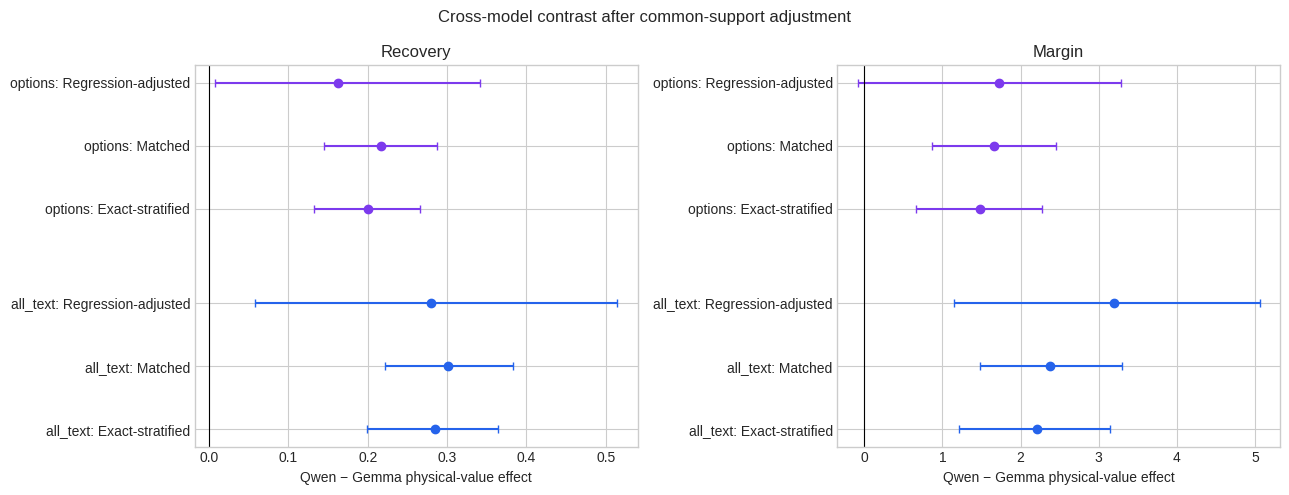

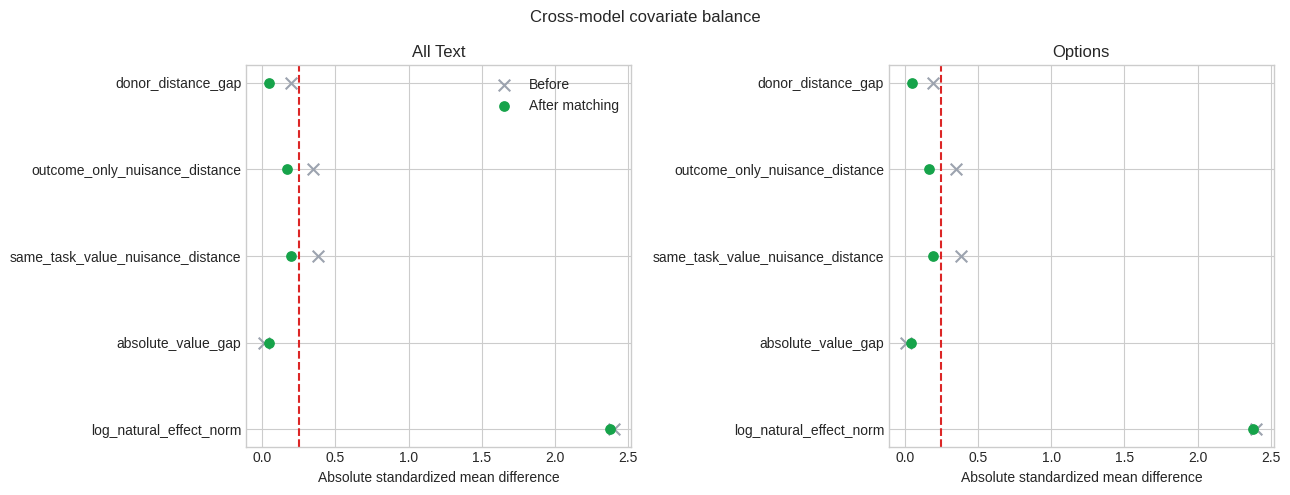

Figures: /content/drive/MyDrive/VisualTorque/results/cross_model/cross_model_common_support_audit_v1/figures


In [10]:
stage('Rendering common-support figures')

plt.style.use('seaborn-v0_8-whitegrid')

eligible_plot = exact_support[exact_support['eligible']].copy()
eligible_plot = eligible_plot.sort_values('common_n_per_model', ascending=True)
figure, axis = plt.subplots(figsize=(10, max(4, 0.45 * len(eligible_plot))))
y = np.arange(len(eligible_plot))
axis.barh(y - 0.18, eligible_plot['Qwen'], height=0.35,
          color='#2563eb', label='Qwen')
axis.barh(y + 0.18, eligible_plot['Gemma'], height=0.35,
          color='#f97316', label='Gemma')
axis.set_yticks(y, eligible_plot['exact_stratum'])
axis.set_xlabel('Successful custom-query pairs')
axis.set_title('Exact edit × task common support')
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(
    FIGURE_DIR / 'exact_common_support_counts.png',
    dpi=200, bbox_inches='tight',
)
plt.show()

primary_exact = stratified_tests[
    stratified_tests['support_level'] == 'exact'
].copy()
primary_matched = matched_tests[np.isinf(
    matched_tests['maximum_distance']
)].copy()
forest_rows = []
for _, row in primary_exact.iterrows():
    forest_rows.append({
        'estimator': 'Exact-stratified', **row[
            ['mapped_site', 'metric', 'effect', 'ci_low', 'ci_high']
        ].to_dict(),
    })
for _, row in primary_matched.iterrows():
    forest_rows.append({
        'estimator': 'Matched', **row[
            ['mapped_site', 'metric', 'effect', 'ci_low', 'ci_high']
        ].to_dict(),
    })
for _, row in regression_tests.iterrows():
    forest_rows.append({
        'estimator': 'Regression-adjusted', **row[
            ['mapped_site', 'metric', 'effect', 'ci_low', 'ci_high']
        ].to_dict(),
    })
forest = pd.DataFrame(forest_rows)
figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, metric in zip(axes, ('recovery', 'margin')):
    subset = forest[forest['metric'] == metric].copy()
    labels = []
    positions = []
    offset = 0
    colors = []
    for site in ('all_text', 'options'):
        for estimator in ('Exact-stratified', 'Matched', 'Regression-adjusted'):
            row = subset[
                (subset['mapped_site'] == site)
                & (subset['estimator'] == estimator)
            ].iloc[0]
            labels.append(f'{site}: {estimator}')
            positions.append(offset)
            colors.append('#2563eb' if site == 'all_text' else '#7c3aed')
            axis.errorbar(
                row['effect'], offset,
                xerr=[[row['effect'] - row['ci_low']],
                      [row['ci_high'] - row['effect']]],
                fmt='o', capsize=3, color=colors[-1],
            )
            offset += 1
        offset += 0.5
    axis.axvline(0, color='black', linewidth=0.8)
    axis.set_yticks(positions, labels)
    axis.set_xlabel('Qwen − Gemma physical-value effect')
    axis.set_title(metric.title())
figure.suptitle('Cross-model contrast after common-support adjustment')
figure.tight_layout()
figure.savefig(
    FIGURE_DIR / 'common_support_estimator_forest.png',
    dpi=200, bbox_inches='tight',
)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for axis, mapped_site in zip(axes, ('all_text', 'options')):
    subset = balance[balance['mapped_site'] == mapped_site].copy()
    y = np.arange(len(subset))
    axis.scatter(subset['before_smd'].abs(), y, label='Before',
                 color='#9ca3af', marker='x', s=70)
    axis.scatter(subset['after_smd'].abs(), y, label='After matching',
                 color='#16a34a', marker='o', s=45)
    axis.axvline(MAX_ACCEPTABLE_SMD, color='#dc2626', linestyle='--')
    axis.set_yticks(y, subset['covariate'])
    axis.set_xlabel('Absolute standardized mean difference')
    axis.set_title(mapped_site.replace('_', ' ').title())
axes[0].legend(frameon=False)
figure.suptitle('Cross-model covariate balance')
figure.tight_layout()
figure.savefig(
    FIGURE_DIR / 'cross_model_covariate_balance.png',
    dpi=200, bbox_inches='tight',
)
plt.show()
print('Figures:', FIGURE_DIR)


In [11]:
stage('Applying frozen audit gate and writing report')

support_sufficient = bool(
    len(eligible_exact) >= MIN_PRIMARY_BLOCKS
    and primary_common_n >= MIN_PRIMARY_COMMON_N
)

def one_row(frame, site, metric):
    rows = frame[
        (frame['mapped_site'] == site) & (frame['metric'] == metric)
    ]
    assert len(rows) == 1, (site, metric, len(rows))
    return rows.iloc[0]

site_decisions = []
for mapped_site in ('all_text', 'options'):
    metric_passes = []
    metric_details = []
    max_smd = float(balance.loc[
        balance['mapped_site'] == mapped_site, 'after_smd'
    ].abs().max())
    for metric in ('recovery', 'margin'):
        exact = one_row(primary_exact, mapped_site, metric)
        matched = one_row(primary_matched, mapped_site, metric)
        regression = one_row(regression_tests, mapped_site, metric)
        leave = leaveout[
            (leaveout['mapped_site'] == mapped_site)
            & (leaveout['metric'] == metric)
        ]
        blocks = block_effects[
            (block_effects['mapped_site'] == mapped_site)
            & (block_effects['metric'] == metric)
        ]
        positive_block_rate = float((blocks['effect'] > 0).mean())
        stable = bool(
            exact['passes_fdr']
            and matched['passes_fdr']
            and regression['passes_fdr']
            and len(leave) == len(eligible_exact)
            and (leave['effect'] > 0).all()
            and positive_block_rate >= 0.75
        )
        metric_passes.append(stable)
        metric_details.append({
            'metric': metric,
            'exact_effect': float(exact['effect']),
            'exact_ci': [float(exact['ci_low']), float(exact['ci_high'])],
            'exact_q': float(exact['q_bh']),
            'matched_effect': float(matched['effect']),
            'matched_ci': [float(matched['ci_low']), float(matched['ci_high'])],
            'matched_q': float(matched['q_bh']),
            'regression_effect': float(regression['effect']),
            'regression_ci': [
                float(regression['ci_low']), float(regression['ci_high'])
            ],
            'regression_q': float(regression['q_bh']),
            'positive_block_rate': positive_block_rate,
            'leave_one_stratum_all_positive': bool(
                len(leave) == len(eligible_exact)
                and (leave['effect'] > 0).all()
            ),
            'stable': stable,
        })
    site_decisions.append({
        'mapped_site': mapped_site,
        'maximum_absolute_smd_after_matching': max_smd,
        'balance_pass': bool(max_smd < MAX_ACCEPTABLE_SMD),
        'metrics': metric_details,
        'full_pass': bool(
            support_sufficient
            and all(metric_passes)
            and max_smd < MAX_ACCEPTABLE_SMD
        ),
    })

any_primary_positive = bool(primary_exact['passes_fdr'].any())
if not support_sufficient:
    decision_code = 'cross_model_common_support_insufficient'
elif any(row['full_pass'] for row in site_decisions):
    decision_code = 'cross_model_difference_common_support_supported'
elif any_primary_positive:
    decision_code = 'cross_model_difference_common_support_inconclusive'
else:
    decision_code = 'cross_model_difference_not_supported_on_common_support'

decision = {
    'schema_version': 'cross-model-common-support-decision-1.0',
    'eligible_exact_blocks': len(eligible_exact),
    'primary_common_n_per_model': primary_common_n,
    'support_sufficient': support_sufficient,
    'site_decisions': site_decisions,
    'decision': decision_code,
    'interpretation_limit': protocol_identity['interpretation_limit'],
    'recommended_next': (
        'If supported, freeze the mapped cross-model difference and proceed '
        'to the weight-by-distance composition experiment. If inconclusive '
        'or insufficient, run a small same-manifest Qwen–Gemma replication '
        'before making a model-specific mechanism claim.'
    ),
}
write_json_atomic(OUTPUT_DIR / 'decision_summary.json', decision)

report_lines = [
    '# Cross-model common-support audit', '',
    f'- Eligible exact edit × task blocks: {len(eligible_exact)}.',
    f'- Common n per model: {primary_common_n}.',
    f'- Support sufficient: {support_sufficient}.',
    f'- Decision: **`{decision_code}`**',
    '', '## Exact support', '',
]
for _, row in exact_support[exact_support['eligible']].iterrows():
    report_lines.append(
        f"- {row['exact_stratum']}: Qwen {int(row['Qwen'])}, "
        f"Gemma {int(row['Gemma'])}, common n={int(row['common_n_per_model'])}."
    )
report_lines.extend(['', '## Estimator triangulation', ''])
for site in site_decisions:
    report_lines.append(
        f"- {site['mapped_site']}: max matched |SMD|="
        f"{site['maximum_absolute_smd_after_matching']:.3f}, "
        f"balance pass={site['balance_pass']}, full pass={site['full_pass']}."
    )
    for metric in site['metrics']:
        report_lines.append(
            f"  - {metric['metric']}: exact {metric['exact_effect']:.3f} "
            f"[{metric['exact_ci'][0]:.3f}, {metric['exact_ci'][1]:.3f}]; "
            f"matched {metric['matched_effect']:.3f} "
            f"[{metric['matched_ci'][0]:.3f}, {metric['matched_ci'][1]:.3f}]; "
            f"regression {metric['regression_effect']:.3f} "
            f"[{metric['regression_ci'][0]:.3f}, "
            f"{metric['regression_ci'][1]:.3f}]; stable={metric['stable']}."
        )
report_lines.extend([
    '', '## Interpretation limit', '',
    protocol_identity['interpretation_limit'], '',
    '## Recommended next step', '',
    decision['recommended_next'], '',
])
report_path = OUTPUT_DIR / 'common_support_audit_report.md'
report_path.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')
display(pd.DataFrame(site_decisions))
print(report_path.read_text('utf-8'))


[10/11] Applying frozen audit gate and writing report


,mapped_site,maximum_absolute_smd_after_matching,balance_pass,metrics,full_pass
0,all_text,2.375142,False,"[{'metric': 'recovery', 'exact_effect': 0.2853...",False
1,options,2.375142,False,"[{'metric': 'recovery', 'exact_effect': 0.2005...",False


# Cross-model common-support audit

- Eligible exact edit × task blocks: 5.
- Common n per model: 70.
- Support sufficient: True.
- Decision: **`cross_model_difference_common_support_inconclusive`**

## Exact support

- add_unit | left_units: Qwen 18, Gemma 16, common n=16.
- add_unit | right_units: Qwen 21, Gemma 18, common n=18.
- mirror | net_torque: Qwen 7, Gemma 5, common n=5.
- redecompose | left_units: Qwen 17, Gemma 15, common n=15.
- redecompose | right_units: Qwen 16, Gemma 17, common n=16.

## Estimator triangulation

- all_text: max matched |SMD|=2.375, balance pass=False, full pass=False.
  - recovery: exact 0.285 [0.199, 0.365]; matched 0.302 [0.222, 0.383]; regression 0.279 [0.058, 0.515]; stable=True.
  - margin: exact 2.207 [1.213, 3.149]; matched 2.375 [1.486, 3.300]; regression 3.192 [1.149, 5.061]; stable=True.
- options: max matched |SMD|=2.375, balance pass=False, full pass=False.
  - recovery: exact 0.201 [0.132, 0.266]; matched 0.217 [0.145, 0.288]; regression 0

In [12]:
stage('Hashing artifacts and finalizing')

expected_outputs = (
    'common_support_protocol.json', 'common_support_strata.csv',
    'stratified_common_support_tests.csv', 'exact_block_effects.csv',
    'leave_one_stratum_out.csv', 'cross_model_matched_pairs.csv',
    'covariate_balance.csv', 'matched_common_support_tests.csv',
    'regression_adjusted_tests.csv', 'decision_summary.json',
    'common_support_audit_report.md',
)
missing = [name for name in expected_outputs if not (OUTPUT_DIR / name).is_file()]
assert not missing, missing
figures = sorted(FIGURE_DIR.glob('*.png'))
assert len(figures) == 3, figures
run_manifest = {
    'schema_version': 'cross-model-common-support-artifacts-1.0',
    'source_hashes': protocol_identity['source_hashes'],
    'outputs': {
        name: sha256_file(OUTPUT_DIR / name) for name in expected_outputs
    },
    'figures': {path.name: sha256_file(path) for path in figures},
    'decision': decision,
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
}
write_json_atomic(OUTPUT_DIR / 'run_manifest.json', run_manifest)
_progress.update(TOTAL_STAGES - _progress.n)
_progress.set_postfix_str('complete')
_progress.close()
print('Complete:', OUTPUT_DIR)


[11/11] Hashing artifacts and finalizing
Complete: /content/drive/MyDrive/VisualTorque/results/cross_model/cross_model_common_support_audit_v1


## Reading the result

A supported decision means the Qwen–Gemma mapped-route difference survives restriction to shared edit/task strata, cross-model difficulty matching, regression adjustment, and leave-one-stratum-out checks.
